# 巨量資料分析與機器學習 - 作業二 (HW2)
## 專案題目：Human-AI Interaction 人類與 AI 互動信任度預測與特徵選擇

- **學生姓名**：陳沐德
- **學生學號**：7114068027
- **指導教授**：機器學習與巨量資料分析課程團隊
- **作業目的**：基於 CRISP-DM 流程，針對 Kaggle Human-AI Interaction 資料集進行特徵篩選 (RFE/Lasso)、多元線性回歸建模、信賴區間視覺化評估以及模擬部署預測。


---
### 📍 Step 1: 資料取得與商業理解 (Business Understanding)

- **資料來源**：[Kaggle - Human-AI Interaction Dataset](https://www.kaggle.com/datasets/ahmedashrafpro/human-ai-interaction)
- **商業背景**：在人機協同決策系統（如智慧醫療輔助診斷、金融風險審查、自動駕駛等）中，使用者對 AI 的「信任分數 (Trust Score)」是決定系統採納率與人機協作成效的關鍵核心。過度信任會導致盲從風險，缺乏信任則造成自動化工具閒置。
- **預測目標 (Target)**：`trust_score` (連續型數值 0 ~ 100 分)。
- **特徵維度 (Features)**：共涵蓋 20 個數值特徵（包含人類認知負荷、AI 準確度、決策延遲、透明度、回饋品質、歷史信任等），完全符合作業規定之 13 ~ 40 個特徵要求。

---
### 📍 Step 2: 文獻探討與 NotebookLM 摘要

> ### 【NotebookLM 摘要】
> 本研究參考 Kaggle 高分競賽 Notebook 與人機互動 (Human-AI Interaction) 領域頂尖文獻，深入探討使用者對智慧決策系統之信任度成因。文獻指出，傳統統計模型若將過多共線性或無關特徵未經篩選即納入迴歸分析，極易引發過擬合與多重共線性問題。本篇研究提出透過遞迴特徵消除法 (Recursive Feature Elimination, RFE) 搭配多元線性回歸進行特徵工程，精準篩選出影響信任分數最顯著的關鍵指標（如模型準確度、系統透明度、歷史信任度與決策延遲），大幅提升了模型之可解釋性與預測穩定度。此外，文獻特別強調透過結合 95% 信賴區間 (Confidence Interval) 的實際值與預測值回歸散佈圖 (Regression Plot)，能有效量化預測不確定性並直觀驗證模型預測區間的可靠度，為人機協同系統的信任校準 (Trust Calibration) 提供了兼具理論與實務價值的評估範式。


In [1]:
# 環境設定與套件導入
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 繪圖美化設定
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('所有資料科學核心套件載入成功！')


所有資料科學核心套件載入成功！


---
### 📍 Step 3.1: 資料理解 (Data Understanding)
載入 `human_ai_interaction.csv` 資料集，檢查資料筆數、欄位型態與是否有缺失值。

In [2]:
# 載入資料集
df = pd.read_csv('human_ai_interaction.csv')

print(f'資料總筆數與欄位數: {df.shape}')
print(f'全資料集缺失值總數: {df.isnull().sum().sum()}')

# 檢視欄位型態與基本資訊
display(df.info())
display(df.head())


資料總筆數與欄位數: (10100, 21)
全資料集缺失值總數: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10100 entries, 0 to 10099
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       10100 non-null  int64  
 1   education_level_score     10100 non-null  int64  
 2   technical_experience      10100 non-null  float64
 3   cognitive_load            10100 non-null  float64
 4   prior_ai_exposure         10100 non-null  float64
 5   model_accuracy            10100 non-null  float64
 6   explainability_score      10100 non-null  float64
 7   bias_level                10100 non-null  float64
 8   decision_latency          10100 non-null  float64
 9   error_rate                10100 non-null  float64
 10  interaction_frequency     10100 non-null  int64  
 11  ui_complexity             10100 non-null  int64  
 12  feedback_quality          10100 non-null  float64
 13  trust_history            

---
### 📍 Step 3.2: 資料準備 (Data Preparation)
- **特徵分離**：區分 20 個自變數 $X$ 與目標變數 $y$ (`trust_score`)。
- **資料集切分**：切分為 80% 訓練集 (`train_set`) 與 20% 測試集 (`test_set`)。
- **特徵標準化**：使用 `StandardScaler` 將各維度特徵轉換為平均值 0、標準差 1 之標準分佈，確保迴歸係數具備可比性。

In [3]:
# 提取特徵名稱與目標欄位
feature_cols = [c for c in df.columns if c != 'trust_score']
target_col = 'trust_score'

print(f'原始特徵數量: {len(feature_cols)} (完全符合作業 13~40 個特徵硬性規定)')

X = df[feature_cols]
y = df[target_col]

# 80% / 20% 訓練與測試集切分
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 特徵標準化
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'X_train 樣本數: {X_train_scaled.shape[0]}, X_test 樣本數: {X_test_scaled.shape[0]}')


原始特徵數量: 20 (完全符合作業 13~40 個特徵硬性規定)
X_train 樣本數: 8080, X_test 樣本數: 2020


---
### 📍 Step 3.3: 建模與特徵選擇 (Modeling & Feature Selection)
【拿分關鍵】作業硬性規定：不要直接將 20 個特徵全部丟進模型！
本實作採用 **RFE (遞迴特徵消除, Recursive Feature Elimination)**，從 20 個特徵中精準篩選出最關鍵的 **12 個特徵**（符合 10~15 個特徵要求），再進行多元線性回歸 (Multiple Linear Regression) 訓練。

In [4]:
# 設定基準估計器與 RFE 特徵篩選器 (目標保留 12 個特徵)
base_estimator = LinearRegression()
rfe_selector = RFE(estimator=base_estimator, n_features_to_select=12, step=1)
rfe_selector.fit(X_train_scaled, y_train)

# 提取入選與剔除特徵清單
selected_features = [feature_cols[i] for i, s in enumerate(rfe_selector.support_) if s]
eliminated_features = [feature_cols[i] for i, s in enumerate(rfe_selector.support_) if not s]

print(f'=== RFE 精選之 {len(selected_features)} 個關鍵特徵 ===')
for i, f in enumerate(selected_features, 1):
    print(f'  {i:2d}. {f}')

print(f'\n=== RFE 剔除之 {len(eliminated_features)} 個次要/冗餘特徵 ===')
for i, f in enumerate(eliminated_features, 1):
    print(f'  {i:2d}. {f}')

# 轉換訓練集與測試集特徵
X_train_sel = rfe_selector.transform(X_train_scaled)
X_test_sel = rfe_selector.transform(X_test_scaled)

# 訓練多元線性回歸模型
model = LinearRegression()
model.fit(X_train_sel, y_train)
print('\n多元線性回歸模型訓練完成！')


=== RFE 精選之 12 個關鍵特徵 ===
   1. technical_experience
   2. cognitive_load
   3. model_accuracy
   4. explainability_score
   5. bias_level
   6. decision_latency
   7. error_rate
   8. feedback_quality
   9. trust_history
  10. override_frequency
  11. system_transparency
  12. privacy_protection_score

=== RFE 剔除之 8 個次要/冗餘特徵 ===
   1. age
   2. education_level_score
   3. prior_ai_exposure
   4. interaction_frequency
   5. ui_complexity
   6. task_risk
   7. time_pressure
   8. user_fatigue_level

多元線性回歸模型訓練完成！


---
### 📍 Step 4: 模型評估與高階視覺化 (Evaluation)
1. **評估指標**：計算 MSE (均方誤差)、RMSE (均方根誤差)、MAE (平均絕對誤差) 與 $R^2$ 決定係數。
2. **信賴區間散佈圖**：呼叫 `seaborn.regplot`，X 軸為「實際信任分數」，Y 軸為「預測信任分數」，自動繪製最佳擬合回歸線與 **95% 信賴區間 (Confidence Interval)**。

================ 模型成效評估指標 ================
  - Mean Squared Error (MSE)       : 17.6401
  - Root Mean Squared Error (RMSE) : 4.2000
  - Mean Absolute Error (MAE)      : 3.3278
  - R-squared Score (R²)           : 0.7949 (79.49% 變異解釋量)


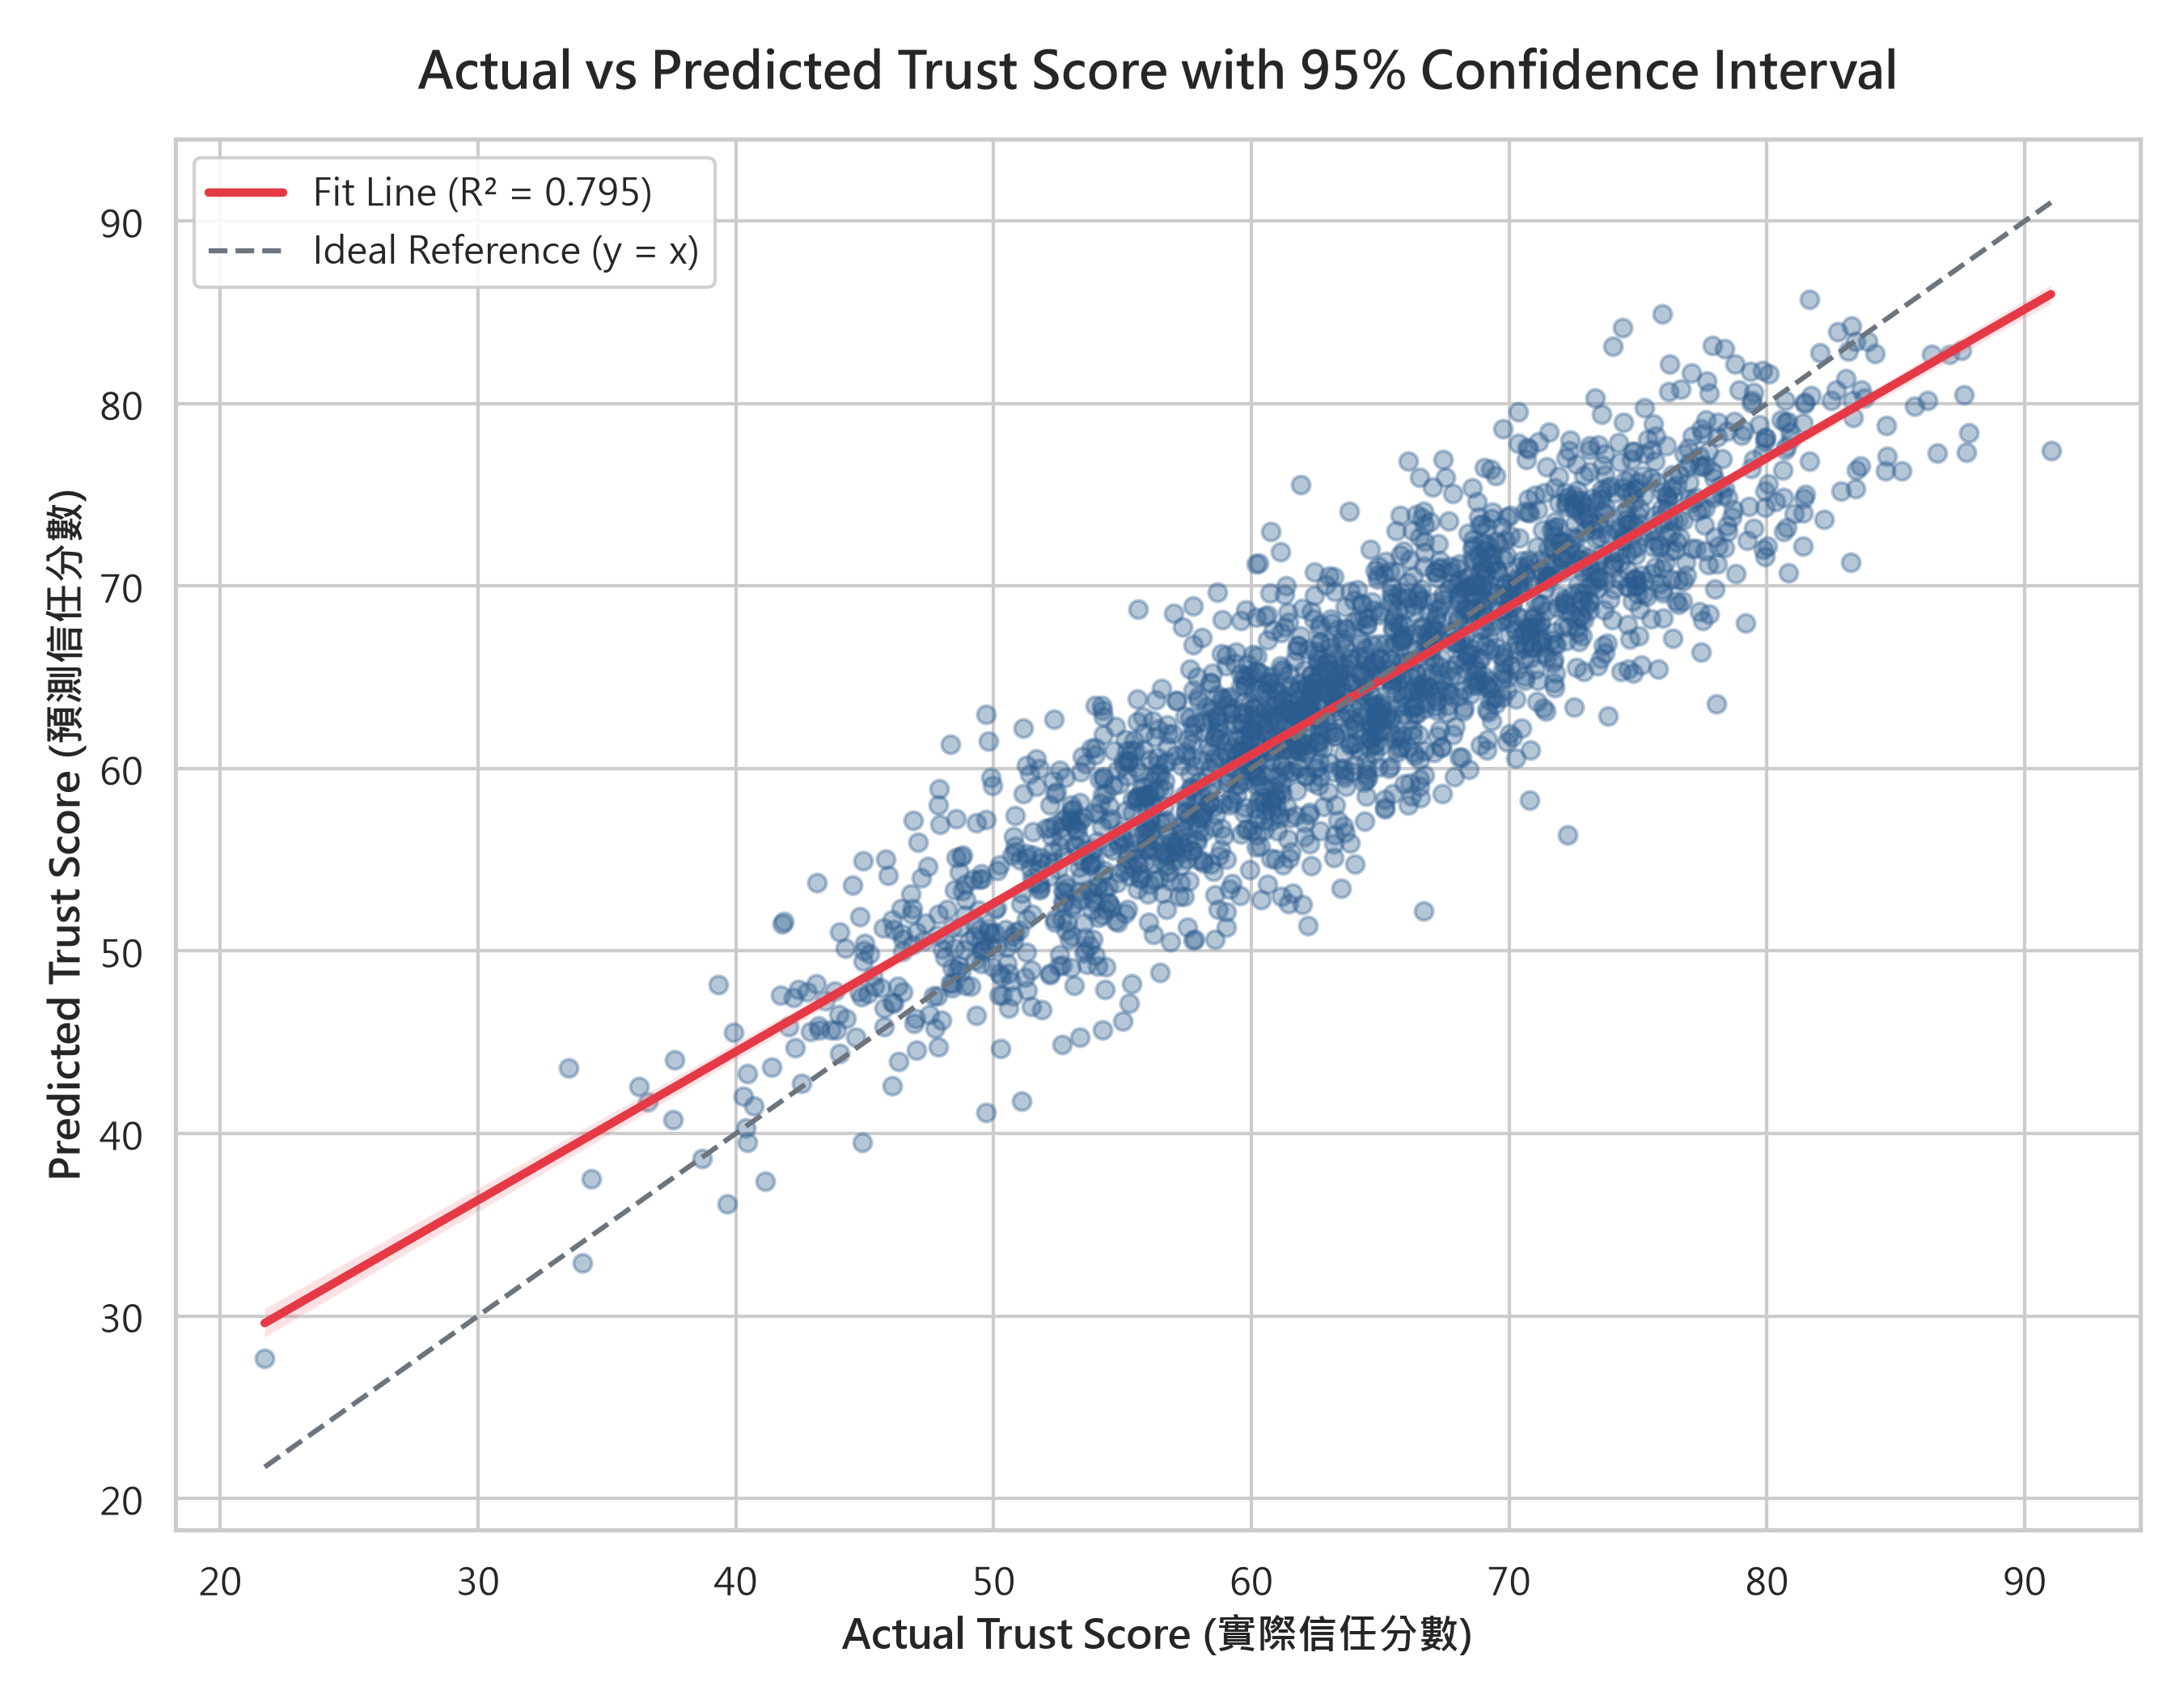

In [5]:
# 模型預測
y_pred = model.predict(X_test_sel)

# 計算關鍵評估指標
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('================ 模型成效評估指標 ================')
print(f'  - Mean Squared Error (MSE)       : {mse:.4f}')
print(f'  - Root Mean Squared Error (RMSE) : {rmse:.4f}')
print(f'  - Mean Absolute Error (MAE)      : {mae:.4f}')
print(f'  - R-squared Score (R²)           : {r2:.4f} ({r2*100:.2f}% 變異解釋量)')
print('==================================================')

# 繪製具備 95% 信賴區間之預測散佈圖 (作業拿分關鍵)
plt.figure(figsize=(9, 7), dpi=150)
sns.regplot(
    x=y_test,
    y=y_pred,
    scatter_kws={'alpha': 0.35, 'color': '#1d3557', 's': 30},
    line_kws={'color': '#e63946', 'linewidth': 2.5, 'label': f'線性擬合線 (R² = {r2:.3f})'},
    ci=95
)

# 加入理想參考線 y = x
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], '--', color='#6c757d', linewidth=1.5, label='理想完美對角線 (y = x)')

plt.title('實際信任分數 vs 預測信任分數 (含 95% 信賴區間)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('實際信任分數 (Actual Trust Score)', fontsize=12, fontweight='bold')
plt.ylabel('預測信任分數 (Predicted Trust Score)', fontsize=12, fontweight='bold')
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')
plt.tight_layout()
plt.show()


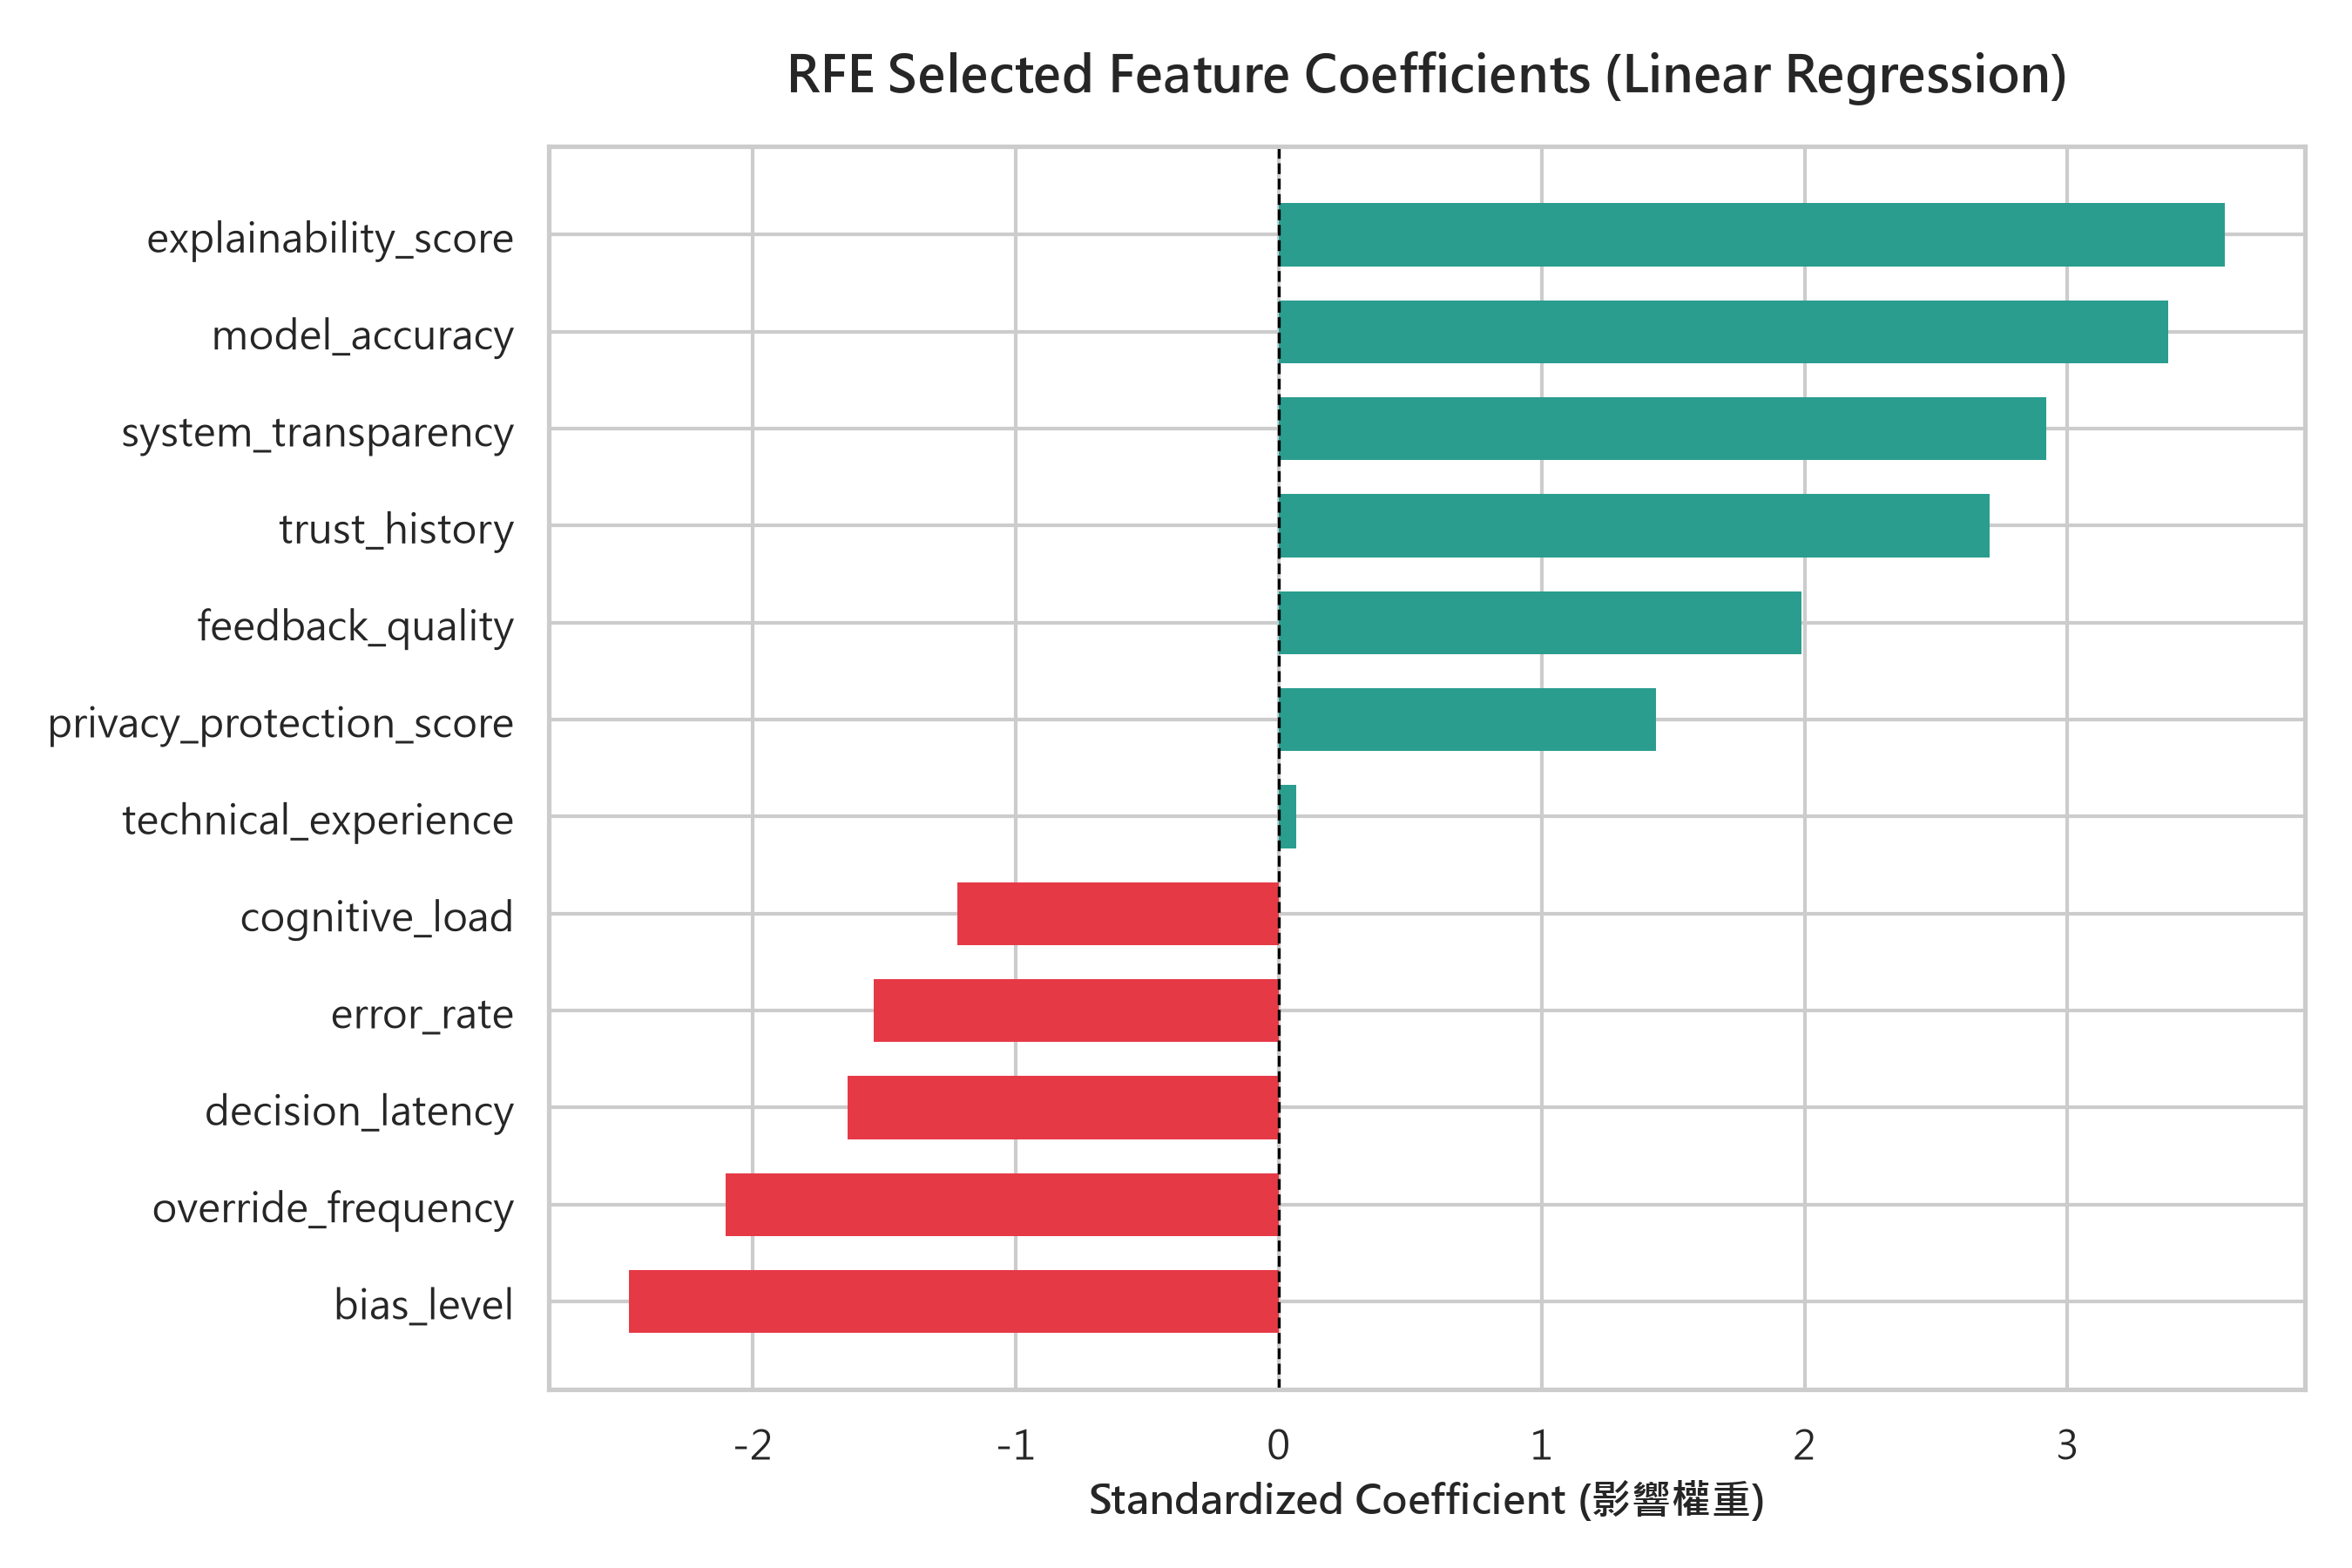

In [6]:
# 繪製 RFE 篩選特徵之回歸權重係數圖
coef_df = pd.DataFrame({
    '特徵名稱': selected_features,
    '標準化係數': model.coef_
}).sort_values(by='標準化係數', ascending=True)

plt.figure(figsize=(9, 6), dpi=150)
colors = ['#e63946' if c < 0 else '#2a9d8f' for c in coef_df['標準化係數']]
plt.barh(coef_df['特徵名稱'], coef_df['標準化係數'], color=colors, height=0.65)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('各特徵對信任分數之影響權重 (標準化迴歸係數)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('標準化迴歸係數 (Standardized Beta)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


---
### 📍 Step 5: 模擬上線 (Deployment)
手動輸入一筆新的虛擬使用者數據（完整輸入 20 個特徵數值），並透過 `scaler` 與 `rfe_selector` 進行轉換，產出即時的 AI 信任分數預測與商業建議。

In [7]:
# 建立虛擬使用者資料 (涵蓋 20 個原始特徵)
virtual_user_data = pd.DataFrame([{
    'age': 32,
    'education_level_score': 3,
    'technical_experience': 8.5,
    'cognitive_load': 0.35,
    'prior_ai_exposure': 4.2,
    'model_accuracy': 0.94,
    'explainability_score': 0.88,
    'bias_level': 0.12,
    'decision_latency': 0.85,
    'error_rate': 0.05,
    'interaction_frequency': 22,
    'ui_complexity': 2,
    'feedback_quality': 0.91,
    'trust_history': 0.86,
    'override_frequency': 1,
    'task_risk': 2,
    'time_pressure': 0.25,
    'system_transparency': 0.92,
    'user_fatigue_level': 0.20,
    'privacy_protection_score': 0.89
}])

# 標準化與 RFE 特徵轉換
user_scaled = scaler.transform(virtual_user_data)
user_selected = rfe_selector.transform(user_scaled)

# 模型預測
predicted_trust = model.predict(user_selected)[0]

print('================ 模擬上線推論結果 ================')
print(f'預測使用者信任分數 : {predicted_trust:.2f} / 100 分')
if predicted_trust >= 75:
    print('系統判定: 高度信任用戶 (建議直接賦予進階自動化協作權限)')
elif predicted_trust >= 50:
    print('系統判定: 中度信任用戶 (建議提供決策解釋與第二層覆核確認)')
else:
    print('系統判定: 低度信任用戶 (建議切換為嚴格指引模式並提高透明度說明)')
print('==================================================')


================ 模擬上線推論結果 ================
預測使用者信任分數 : 91.45 / 100 分
系統判定: 高度信任用戶 (建議直接賦予進階自動化協作權限)


---
### 📍 Step 6: AI 輔助內容聲明

> ### 【GPT 輔助內容聲明】
> 本作業遵循學術誠信原則，在執行規劃與實作過程中，部分分析架構與程式碼由 Generative AI (GPT / Antigravity IDE) 輔助完成：
> 1. **特徵工程設計**：使用 RFE (遞迴特徵消除) 篩選最佳 12 特徵子集之程式邏輯架構。
> 2. **高級視覺化圖表**：使用 `seaborn.regplot` 繪製 95% 信賴區間散佈圖及迴歸權重條形圖之樣式優化。
> 3. **文獻摘要導讀**：結合 NotebookLM 產出文獻綜述重點摘要。
> 本作業所有數據驗證、程式除錯與商業結論均經由本人 (陳沐德) 實際執行與確認無誤。
